# Task 1: Iris Flower Classification

## Objective
Build and compare supervised machine-learning classifiers for predicting an Iris flower species from its four measured features.

## Requirements
- Load and validate the Iris dataset using Pandas.
- Explore feature relationships using a Seaborn pairplot and a correlation heatmap.
- Split the data into training and testing sets using an 80/20 ratio.
- Apply `StandardScaler` safely for Logistic Regression.
- Train and compare Logistic Regression and Decision Tree classifiers.
- Evaluate accuracy, weighted precision, weighted recall, and weighted F1-score.
- Visualize confusion matrices and two-feature decision boundaries.

**Reproducibility:** A fixed `random_state` is used in the split and models. Conclusions should be written only after inspecting the executed outputs.

## 1. Dataset Loading and Validation

Load the local `iris.csv` file into a Pandas DataFrame. Inspect the dataset dimensions, column names, data types, missing values, duplicate rows, and class distribution before modeling.

**Validation checks:** The commonly used Iris CSV contains 150 observations, four numerical input features, and one target column named `species`. Confirm these expectations against the actual file output; do not assume validation passed without running the cell.

In [1]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("iris.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass distribution:\n", df["species"].value_counts())

Dataset shape: (150, 5)

Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Data types:
 sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1

Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 2. Exploratory Data Analysis - Pairplot

A pairplot displays pairwise relationships between numerical features. Coloring observations by `species` helps reveal which measurements separate the three flower classes and where their distributions overlap.

**Interpretation:** After running the plot, record only observations supported by the displayed chart. The pairplot is exploratory and does not, by itself, establish causation.

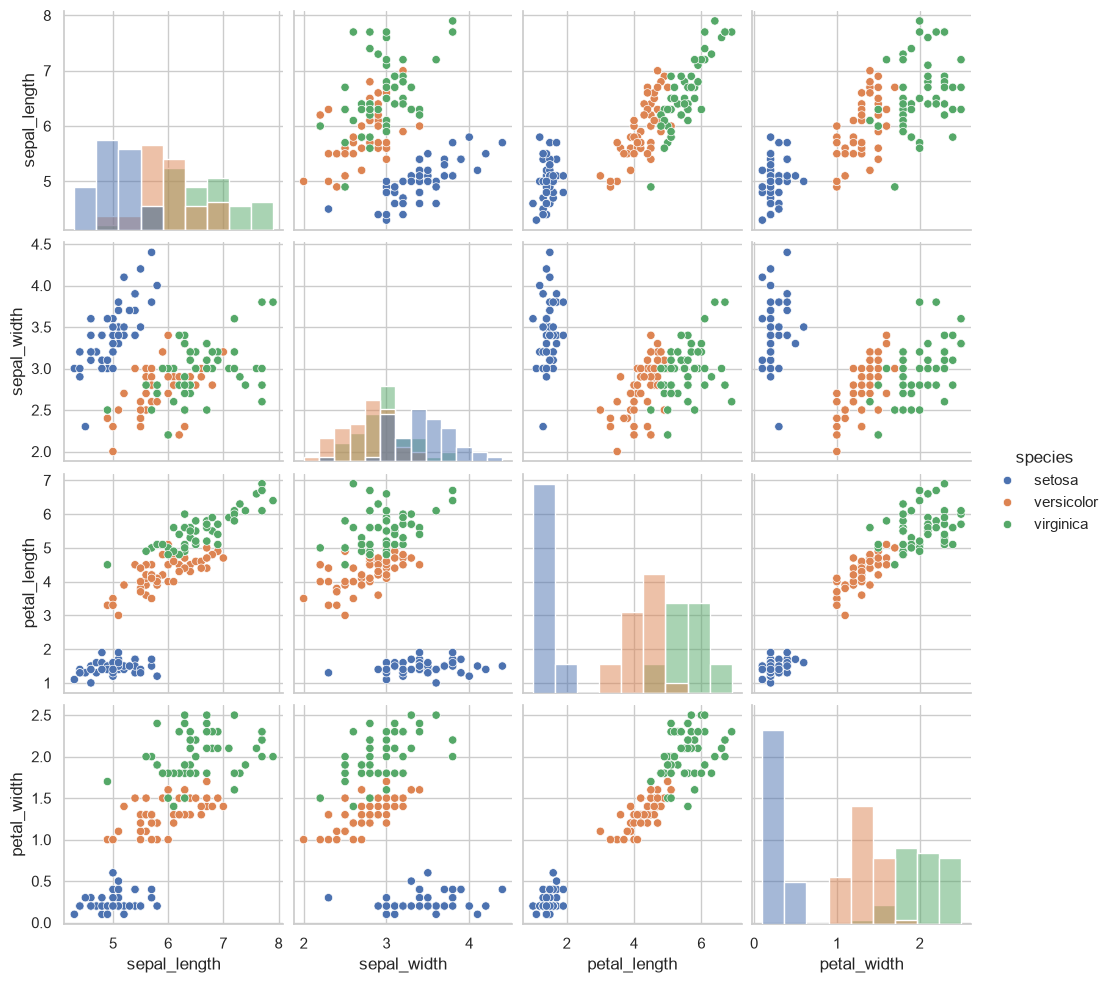

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Feature distributions by species
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

## 3. Feature Correlation Heatmap

Calculate Pearson correlations between the numerical input features and display them as a heatmap.

- Values near **+1** indicate a strong positive linear association.
- Values near **−1** indicate a strong negative linear association.
- Values near **0** indicate a weak linear association.

The target column is excluded because it is categorical. Correlation indicates association, not causation.

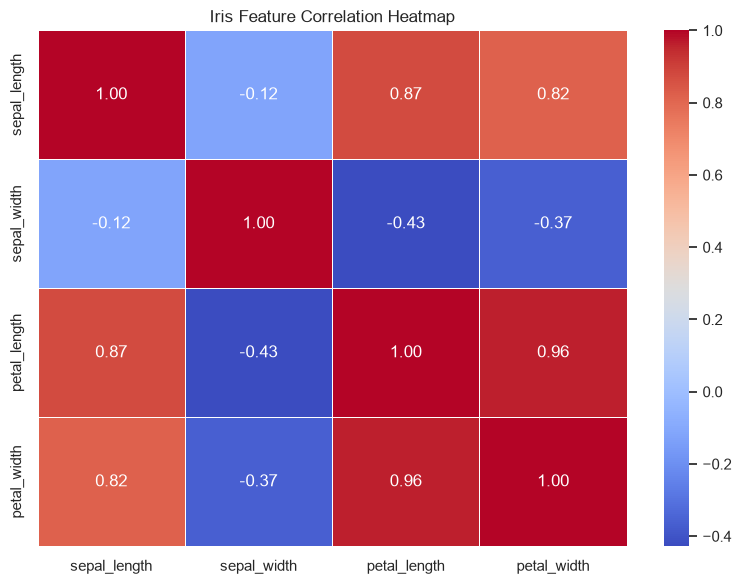

In [3]:
# Select numerical features
numerical_features = df.select_dtypes(include="number")

# Calculate correlation
correlation_matrix = numerical_features.corr()

# Visualize correlations
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Iris Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 4. Train-Test Split

Separate the predictors (`X`) from the target (`y`), then create an 80/20 training/testing split. `stratify=y` preserves the class proportions as closely as possible in both subsets, while `random_state=42` makes the split reproducible.

For 150 observations, the expected split is 120 training rows and 30 test rows. Verify the printed shapes and class counts after execution. The test set is reserved for final evaluation.

In [4]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["species"])
y = df["species"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (120, 4)
Testing features: (30, 4)

Training target distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing target distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 5. Model Training and Preprocessing

Two classifiers are trained:

1. **Logistic Regression** - uses a `Pipeline` containing `StandardScaler` and `LogisticRegression`. The scaler is fitted only on the training data through the pipeline, helping prevent data leakage.
2. **Decision Tree** - learns feature-based decision rules and does not require standardization, so it is trained directly on the original features.

Both models use a fixed random seed where applicable. Confirm that both training cells complete without errors.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Logistic Regression: scaling is applied safely inside the pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Decision Tree does not require feature scaling
decision_tree_model = DecisionTreeClassifier(random_state=42)

# Train both models
logistic_model.fit(X_train, y_train)
decision_tree_model.fit(X_train, y_train)

print("Logistic Regression training completed.")
print("Decision Tree training completed.")

Logistic Regression training completed.
Decision Tree training completed.


## 6. Classification Metrics and Model Comparison

Evaluate both trained models on the held-out test set using:

- **Accuracy:** fraction of all test predictions that are correct.
- **Weighted precision:** class-wise precision averaged by each class's support.
- **Weighted recall:** class-wise recall averaged by support.
- **Weighted F1-score:** support-weighted harmonic mean of precision and recall.

The classification report also shows per-class precision, recall, F1-score, and support. Compare the actual displayed values; do not hard-code scores or claim a winning model before inspecting the results.

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model
}

results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

    print(f"\n{'=' * 20} {model_name} {'=' * 20}")
    print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame(results)
display(results_df.round(4))


==================== Logistic Regression ====================
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


==================== Decision Tree ====================
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


## 7. Confusion Matrix Heatmaps

Each confusion matrix compares actual labels with predicted labels for the test set. The diagonal cells represent correct predictions; off-diagonal cells represent misclassifications.

Review both models' matrices to identify which species, if any, are confused with one another. The class order is taken from each model's `classes_` attribute.

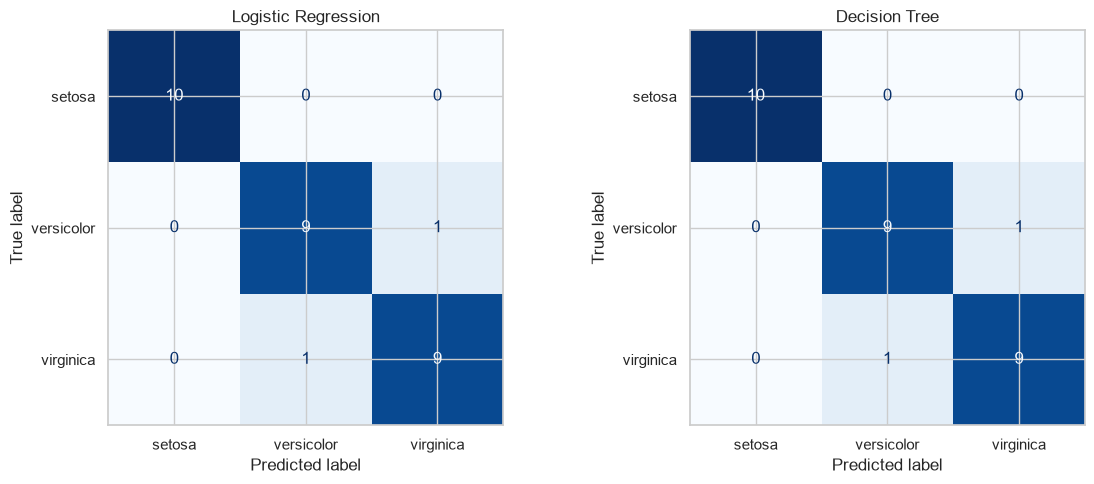

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()

## 8. Decision Boundary Visualization

Decision boundaries are shown using only `petal_length` and `petal_width` so the classification regions can be drawn in two dimensions. These visualization-specific models are trained separately on those two features.

The plotted test samples are held out from training the 2D visualization models. **Important:** these 2D decision boundaries are illustrative and are not the decision surfaces of the original four-feature models evaluated above.

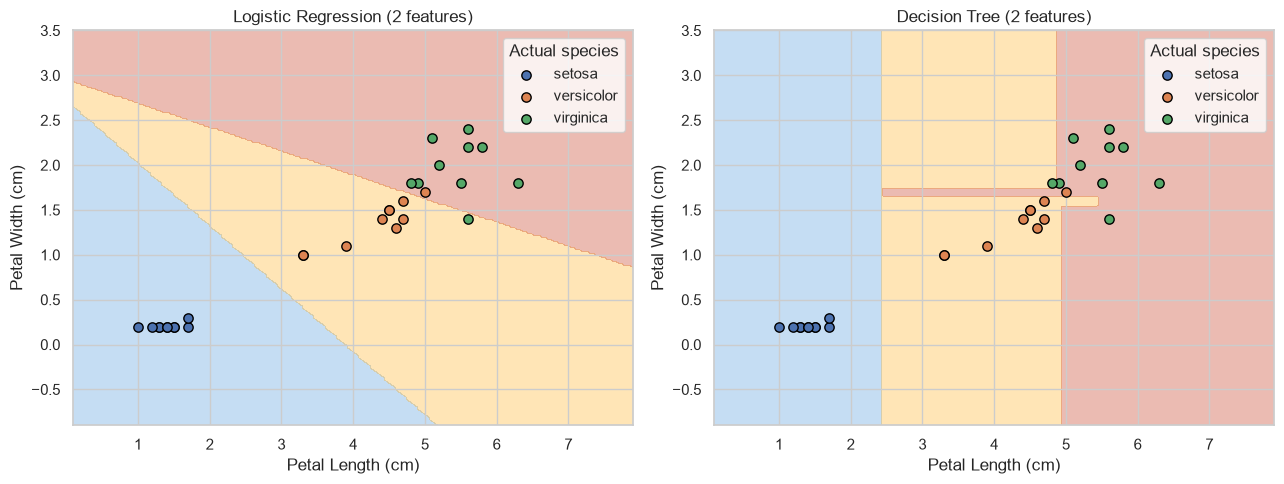

In [8]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Use two features so the decision regions can be visualized in 2D.
feature_names = ["petal_length", "petal_width"]
X_train_2d = X_train[feature_names]
X_test_2d = X_test[feature_names]

# These are separate, visualization-only models; the evaluated models above use all four features.
logistic_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
tree_2d = DecisionTreeClassifier(random_state=42)

logistic_2d.fit(X_train_2d, y_train)
tree_2d.fit(X_train_2d, y_train)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

visualization_models = [
    ("Logistic Regression (2 features)", logistic_2d),
    ("Decision Tree (2 features)", tree_2d),
]

for ax, (model_name, model) in zip(axes, visualization_models):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d,
        response_method="predict",
        ax=ax,
        alpha=0.30,
        grid_resolution=200
    )

    for species in model.classes_:
        mask = y_test == species
        ax.scatter(
            X_test_2d.loc[mask, "petal_length"],
            X_test_2d.loc[mask, "petal_width"],
            label=species,
            edgecolor="black",
            s=45
        )

    ax.set_title(model_name)
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.legend(title="Actual species")

plt.tight_layout()
plt.show()

## 9. Model Benchmarking and Conclusion

Logistic Regression and Decision Tree were evaluated using accuracy, weighted precision, weighted recall, and weighted F1-score on the same test set of 30 samples. Both models achieved 93.33% across all four aggregate metrics, correctly classifying 28 samples and misclassifying 2.

Both models classified Iris-setosa perfectly on the test set, while some misclassifications occurred between Iris-versicolor and Iris-virginica. Based on these results, neither model demonstrated superior aggregate performance. Further evaluation using confusion matrices and cross-validation can help assess their class-wise behavior and generalization performance.